# IT135IU - INTRODUCTION TO DATA SCIENCE
## PROJECT DELIVERABLE 2: DATA AND PROFILING
### Instructor: Nguyen Thi Thuy Loan
**Topic 14:** Amazon Customer Reviews Analysis (Book Category)

---
### TEAM MEMBERS & ROLES
1. **Nguyễn Đỗ Nam Trà** (ITDSIU25049) - Product Owner (Leader)
2. **Bùi Văn Lợi** (ITDSIU25021) - Data Engineer
3. **Nguyễn Thế Hào** (TDSIU22139) - Data Analyst
4. **Phạm Ngọc Minh Khoa** (ITDSIU25015) - Reproducibility Lead
5. **Nguyễn Trọng Quý** (ITDSIU25037) - Visualization Lead
6. **Trần Như Phú** (ITDSIU25027 ) - Ethics & Privacy Officer

---
### DECISION QUESTION
> *Should Amazon product category managers invest in NLP sentiment extraction to identify product flaw patterns early, or rely solely on average star ratings?*

## 1. DATASET LOADING & SETUP


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [4]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

In [5]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"teafrost","key":"fdc2fcd69c2739aab9c73df9c74019b6"}'}

In [6]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [7]:
!kaggle datasets download -d nguynthehao/amazon-book-reviews

Dataset URL: https://www.kaggle.com/datasets/nguynthehao/amazon-book-reviews
License(s): unknown
100% 1.38G/1.38G [01:23<00:00, 17.8MB/s]



In [8]:
!unzip amazon-book-reviews.zip -d /content/amazon-book-reviews

Archive:  amazon-book-reviews.zip
  inflating: /content/amazon-book-reviews/amazon_reviews_multilingual_US_v1_00.tsv  


In [9]:
file_path = '/content/amazon-book-reviews/amazon_reviews_multilingual_US_v1_00.tsv'
df = pd.read_csv(file_path, sep='\t', on_bad_lines='skip')
#the first 5 rows
print(df.shape)
df.head()

(6900886, 15)


,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,vine,verified_purchase,review_headline,review_body,review_date
0,US,53096384,R63J84G1LOX6R,1563890119,763187671,The Sandman Vol. 1: Preludes and Nocturnes,Books,4.0,0.0,1.0,N,N,ignore the review below,this is the first 8 issues of the series. it is the starting point of all this... it also contains the sound of her wings. issue #8. which is the first appearance of death. and many peoples favorite issue. its not the best of the collected works. but its the start of them.,1995-08-13
1,US,53096399,R1BALOA11Z06MT,1559947608,381720534,The 22 Immutable Laws of Marketing,Books,4.0,0.0,0.0,N,N,awesome,"I've always been partial to immutable laws. The tape is entertaining, good car listening. The laws are clearly self evident once you've heard them and you wonder why you didn't know all that already and were about to go off and do something stupid. It's cheap, get it.",1995-08-17
2,US,53096332,R1LLAY5W5PZUS4,0671701800,860650224,Contact,Books,5.0,1.0,2.0,N,N,Read the book. It's good.,"This is a book about first contact with aliens, written by a prominent member of SETI, the Search for ExtraTerrestrial Intelligence. Sagan makes excellent use of SETI's current search methods as well as his own knowledge of astronomy and physics to bring a sense of reality to the book. But above its literacy, philosophy, and speculation, it is an entertaining story that is not overshadowed by gadgetry.",1995-08-30
3,US,53096335,R3R9VTJ82FXECQ,0425132153,624269601,Good Omens,Books,5.0,0.0,0.0,N,N,Funniest book ever written about the Anti-Christ,"This is quite possibly *the* funniest book I have ever read. Terry Pratchett is an absolute genius (read the Discworld books--NOW!), and Gaiman manages to give the book the appropriate dark touches. Brilliant",1995-09-11
4,US,51747709,R1P5J3FNBWTFXY,0517122707,161411385,A Confederacy of Dunces,Books,5.0,0.0,0.0,N,N,A winner that didn't last. Only a mothers love remained,"The story behind the book is almost better than the work. But make no mistake, the work will endure.",1995-10-17


## 2. DATA PROFILE TABLE


In [10]:
print(f"--- DATA OVERALL ---")
print(f"Total Rows(Rows): {df.shape[0]}")
print(f"Total Columns(Columns): {df.shape[1]}")
print("-" * 30)
profile_data = []
for col in df.columns:
    profile_data.append({
        'Column': col,
        'Data Type': df[col].dtype,
        'Non-Null Count': df[col].notnull().sum(),
        'Null Count': df[col].isnull().sum(),
        'Unique Values': df[col].nunique(),
        'Min / Start Date': df[col].min() if df[col].dtype != 'object' else '-',
        'Max / End Date': df[col].max() if df[col].dtype != 'object' else '-'
    })

data_profile_df = pd.DataFrame(profile_data)
data_profile_df


--- DATA OVERALL ---
Total Rows(Rows): 6900886
Total Columns(Columns): 15
------------------------------


,Column,Data Type,Non-Null Count,Null Count,Unique Values,Min / Start Date,Max / End Date
0,marketplace,object,6900886,0,1,-,-
1,customer_id,int64,6900886,0,4097784,10001,53096589
2,review_id,object,6900886,0,6900886,-,-
3,product_id,object,6900886,0,86813,-,-
4,product_parent,int64,6900886,0,16310,225472,999988076
5,product_title,object,6900886,0,52326,-,-
6,product_category,object,6900886,0,39,-,-
7,star_rating,float64,6900885,1,5,1.0,5.0
8,helpful_votes,float64,6900885,1,1569,0.0,27550.0
9,total_votes,float64,6900885,1,1712,0.0,28727.0


## 3. DATA CLEANING LOG

### Cleaning Action 1: Handling Missing Values
- **Reason:** Required for analysis and modeling.
- **Action:** Remove rows with missing core information (star_rating, product_title, review_headline, review_body)

### Cleaning Action 2: Remove Duplicates
- **Reason:** Prevent bias in statistical results.
- **Action:** Drop completely duplicated review rows

### Cleaning Action 3: Filter Verified Purchases
- **Reason:** Ensure that the analysis relies strictly on authentic and reliable customer feedback.
- **Action:** Remove all non-verified reviews ('verified_purchase != 'Y'')

### Cleaning Action 4: Helpful Vote Thresholding / Quality Filtering
- **Reason:** Filter out low-quality or potential spam content
- **Action:** Remove reviews with fewer than 3 helpful votes

### Cleaning Action 5: Data Type Casting
- **Reason:** For time-based analysis and sorting.
- **Action:** Convert review_date to datetime format

### Cleaning Action 6: Text Filtering
- **Reason:** Filter out potential spam or marketer links and ensure data quality.
- **Action:** Remove reviews containing HTML tags or URLs

In [11]:
#action 1
# Drop any rows that don't have star ratings, product_titles, review_headlines or review_body
df = df.dropna(subset=["star_rating", "product_title", "review_headline", "review_body"])
print("Datapoint entries: ", df.shape[0])

Datapoint entries:  6900062


In [12]:
#action2
# Remove duplicates
initial_count = df.shape[0]
df = df.drop_duplicates()
print(f"Removed {initial_count - df.shape[0]} duplicate rows.")

Removed 0 duplicate rows.


In [13]:
#action3
#get rid of any non-verified reviews,
# so we can be more certain that the reviews we think are real, are real.

# first reset the index when using .index attribute, ensures index is unique
df.reset_index()
df = df.drop(df[df.verified_purchase != 'Y'].index)
print("Datapoint entries: ", df.shape[0])

Datapoint entries:  5032798


In [14]:
#action4
# We'll also look for something to have at least 3 "helpful" upvotes on
# the reviews as a proxy for them being likely genuine.  Stuff that's too
# spammy/markety probably won't get marked as helpful.

# first reset the index when using .index attribute, ensures index is unique
df.reset_index()
df = df.drop(df[df.helpful_votes < 3].index)
print("Datapoint entries: ", df.shape[0])

Datapoint entries:  319359


In [15]:
#action 5
# Cast review_date to datetime format
df['review_date'] = pd.to_datetime(df['review_date'], errors='coerce')

# Cast star_rating to numeric
df['star_rating'] = pd.to_numeric(df['star_rating'], errors='coerce')

df = df.reset_index(drop=True)
print("Number of rows after quality filtering: ", df.shape[0])

Number of rows after quality filtering:  319359


In [16]:
#action6
#delete any reviews that contain html tags or urls.
#Our hunch is these aren't common in a legit review, and urls
# seem like they'd be abused by marketers linking out, so this
# can be another cheap form of pruning anything but real reviews.
# Re-index since we've dropped many.  Probably not necessary.
df.reset_index()

# Amazon has already converted the opening tags of HTML into &lt;, but not the closing tag,
# e.g. &lt;a href="blah">, so we can just look for this simple pattern and drop rows that
# contain it.  This will automatically cover urls too.
html_delete = "&lt;.*?>"
# Can use the .str.contains() method
df = df.drop(df[df.review_headline.str.contains(html_delete)].index)
print("Datapoint entries: ", df.shape[0])

Datapoint entries:  319357


 ## 4. DATA MANIPULATION OPERATIONS (3 to 5 Operations)


In [17]:
# Filter reviews with star_rating between 3 and 5
df_filtered_rating = df[df['star_rating'].between(3, 5)].copy()
print("Number of rows after filtering star ratings (3-5):", df_filtered_rating.shape[0])


Number of rows after filtering star ratings (3-5): 220398


In [18]:
# Group by product_category to calculate average star rating and total reviews
category_summary = df.groupby('product_category').agg(
    avg_star_rating=('star_rating', 'mean'),
    total_reviews=('review_id', 'count')
).reset_index()

category_summary

,product_category,avg_star_rating,total_reviews
0,Apparel,2.750000,4
1,Automotive,3.736842,19
2,Baby,3.641593,226
3,Books,3.565273,47179
4,Camera,3.733383,1354
5,Digital_Ebook_Purchase,2.839933,39321
6,Digital_Music_Purchase,4.166428,5594
7,Digital_Video_Download,2.506716,21961
8,Electronics,3.564336,987
9,Health & Personal Care,2.990196,102


In [19]:
# Create review_length column to count characters in review_body
df['review_length'] = df['review_body'].astype(str).apply(len)

# Preview the new column
df[['review_body', 'review_length']].head(1)

,review_body,review_length
0,This book can show you the way of how to put all questions in a correct perspective. It's amazing how a almost illetrate man can have such a deep thinking. You seldom find any citation of another thinker or philosopher. Nisargadatta speaks of his own personal experience. Try it. It can add a lot on your thinking way of understand the &quot;world&quot; around you.,365


In [20]:
# 1. Define keyword lists for both directions
positive_keywords = ['good', 'great', 'excellent', 'amazing', 'love', 'wonderful', 'best', 'perfect']
negative_keywords = ['bad', 'worst', 'terrible', 'awful', 'horrible', 'poor', 'disappointing', 'hate']

# 2. Create Column 1: High Rating (4-5 stars) but contains negative words
def check_negative_mismatch(row):
    if row['star_rating'] >= 4.0:
        body_lower = str(row['review_body']).lower()
        if any(word in body_lower for word in negative_keywords):
            return 1
    return 0

df['high_rating_negative_flag'] = df.apply(check_negative_mismatch, axis=1)

# 3. Create Column 2: Low Rating (1-2 stars) but contains positive words
def check_positive_mismatch(row):
    if row['star_rating'] <= 2.0:
        body_lower = str(row['review_body']).lower()
        if any(word in body_lower for word in positive_keywords):
            return 1
    return 0

df['low_rating_positive_flag'] = df.apply(check_positive_mismatch, axis=1)

# 4. Check totals for each mismatch type
print("Number of high-rated reviews containing negative keywords:", df['high_rating_negative_flag'].sum())
print("Number of low-rated reviews containing positive keywords:", df['low_rating_positive_flag'].sum())

Number of high-rated reviews containing negative keywords: 22043
Number of low-rated reviews containing positive keywords: 36903


## 5. Save Output
### 5.1. Save Cleaned Data for Reporting and Web Display
- Export the full processed dataframe (`df_webDisplay`) containing **319,357 rows** to a CSV file (`amazon_reviews_webDisplay.csv`) with index retention (`id`), suitable for exploratory data analysis, reporting dashboards, and web visualization.
### 5.2. Save Processed Data for Machine Learning Modeling
- Export the class-balanced dataframe (`df_modeling`) containing **137,755 rows** (evenly distributed across 5 star-rating classes) to a CSV file (`amazon_reviews_modeling.csv`), ready to be used as input features for machine learning and NLP sentiment classification models.

### 5.1. Save Cleaned Data for Reporting and Web Display

In [21]:
# Convert review_date to datetime format and sort in ascending order
df['review_date'] = pd.to_datetime(df['review_date'])
df = df.sort_values(by='review_date', ascending=False)

# Reset index to start counting from 1 instead of 0
df = df.reset_index(drop=True)
df.index = df.index + 1
df.index.name = 'id'  # Set the primary index column name

In [22]:
df_webDisplay = df.copy()

In [23]:
df_webDisplay.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319357 entries, 1 to 319357
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   marketplace                319357 non-null  object        
 1   customer_id                319357 non-null  int64         
 2   review_id                  319357 non-null  object        
 3   product_id                 319357 non-null  object        
 4   product_parent             319357 non-null  int64         
 5   product_title              319357 non-null  object        
 6   product_category           319357 non-null  object        
 7   star_rating                319357 non-null  float64       
 8   helpful_votes              319357 non-null  float64       
 9   total_votes                319357 non-null  float64       
 10  vine                       319357 non-null  object        
 11  verified_purchase          319357 non-null  object  

star_rating
5.0    150144
1.0     71408
4.0     41201
3.0     29053
2.0     27551
Name: count, dtype: int64


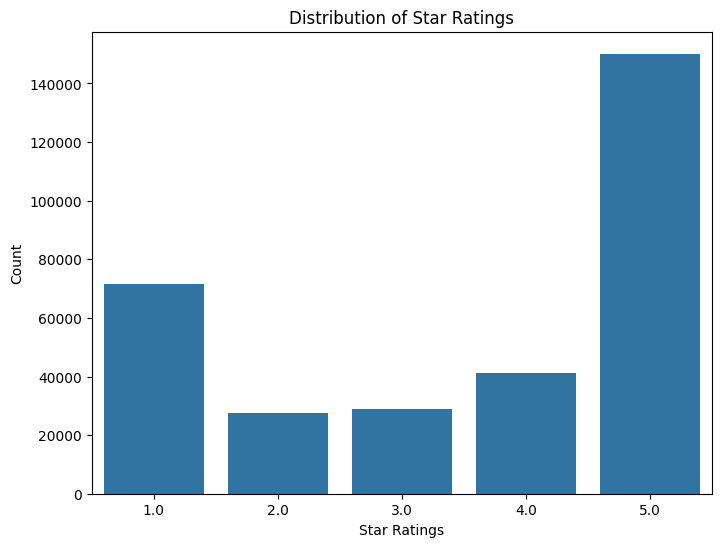

In [24]:
# General function to generate column chart for any given attribute
def column_chart(attribute, label):
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df_webDisplay, x=attribute)
    plt.xlabel(label)
    plt.ylabel('Count')
    plt.title(f'Distribution of {label}')
    plt.show()

print(df_webDisplay['star_rating'].value_counts())
column_chart('star_rating', 'Star Ratings')

In [25]:
# 1. Print dataset general overview (Total rows and columns)
print(f"DATA OVERALL")
print(f"Total Rows (Rows): {df_webDisplay.shape[0]}")
print(f"Total Columns (Columns): {df_webDisplay.shape[1]}")
print("-" * 30)

# 2. Create detailed Data Profile table for each column
profile_data = []
for col in df_webDisplay.columns:
    profile_data.append({
        'Column': col,
        'Data Type': df_webDisplay[col].dtype,
        'Non-Null Count': df_webDisplay[col].notnull().sum(),
        'Null Count': df_webDisplay[col].isnull().sum(),
        'Unique Values': df_webDisplay[col].nunique(),
        'Min / Start Date': df_webDisplay[col].min() if df_webDisplay[col].dtype != 'object' else '-',
        'Max / End Date': df_webDisplay[col].max() if df_webDisplay[col].dtype != 'object' else '-'
    })

data_profile_df = pd.DataFrame(profile_data)
data_profile_df

DATA OVERALL
Total Rows (Rows): 319357
Total Columns (Columns): 18
------------------------------


,Column,Data Type,Non-Null Count,Null Count,Unique Values,Min / Start Date,Max / End Date
0,marketplace,object,319357,0,1,-,-
1,customer_id,int64,319357,0,267347,10099,53096584
2,review_id,object,319357,0,319357,-,-
3,product_id,object,319357,0,33463,-,-
4,product_parent,int64,319357,0,13687,225472,999988076
5,product_title,object,319357,0,25191,-,-
6,product_category,object,319357,0,34,-,-
7,star_rating,float64,319357,0,5,1.0,5.0
8,helpful_votes,float64,319357,0,1302,3.0,27550.0
9,total_votes,float64,319357,0,1420,3.0,28727.0


In [26]:
# Export the DataFrame for Web Display to a CSV file
webDisplay_output_path = 'amazon_reviews_webDisplay.csv'

# Set index=True to retain the index/ID column in the output CSV
df_webDisplay.to_csv(webDisplay_output_path, index=True)

print(f"--- 5.1. REPORTING DATASET ---")
print(f"Successfully exported to: {webDisplay_output_path}")
print(f"Total rows exported: {df_webDisplay.shape[0]}")
print("-" * 40)

--- 5.1. REPORTING DATASET ---
Successfully exported to: amazon_reviews_webDisplay.csv
Total rows exported: 319357
----------------------------------------


### 5.2. Save Processed Data for Machine Learning Modeling

In [27]:
# shuffle all the rows first, fraction of 1 (100%)
df = df.sample(frac=1, random_state=SEED)

# How many examples we want from each star-rating class
num_samples = 27551

# Drop everything after the first K samples, for each star rating
df.drop(df[df.star_rating == 5.0].index[num_samples:], inplace=True)
df.drop(df[df.star_rating == 4.0].index[num_samples:], inplace=True)
df.drop(df[df.star_rating == 3.0].index[num_samples:], inplace=True)
df.drop(df[df.star_rating == 2.0].index[num_samples:], inplace=True)
df.drop(df[df.star_rating == 1.0].index[num_samples:], inplace=True)

df['star_rating'].value_counts()

,count
star_rating,
2.0,27551
4.0,27551
5.0,27551
3.0,27551
1.0,27551


In [28]:
# Convert review_date to datetime format and sort in ascending order
df['review_date'] = pd.to_datetime(df['review_date'])
df = df.sort_values(by='review_date', ascending=False)

# Reset index to start counting from 1 instead of 0
df = df.reset_index(drop=True)
df.index = df.index + 1
df.index.name = 'id'  # Set the primary index column name

In [29]:
df_modeling = df.copy()

In [30]:
# Reproducibility check: fingerprint of the modeling dataset
import hashlib

print("First 5 review_ids:", df_modeling['review_id'].head(5).tolist())
fingerprint = hashlib.md5(''.join(sorted(df_modeling['review_id'])).encode()).hexdigest()
print("Fingerprint:", fingerprint)

First 5 review_ids: ['R25CRPGK0ZMKJ3', 'RAERVMB5F7O47', 'R2GQ9IQ04DWXOC', 'R146MOK7BQ3C5Z', 'RMXQGP7OP2ZXZ']
Fingerprint: 13f81d89b43c4fcfa40ad5dd43c6b6d5


In [31]:
df_modeling.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137755 entries, 1 to 137755
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   marketplace                137755 non-null  object        
 1   customer_id                137755 non-null  int64         
 2   review_id                  137755 non-null  object        
 3   product_id                 137755 non-null  object        
 4   product_parent             137755 non-null  int64         
 5   product_title              137755 non-null  object        
 6   product_category           137755 non-null  object        
 7   star_rating                137755 non-null  float64       
 8   helpful_votes              137755 non-null  float64       
 9   total_votes                137755 non-null  float64       
 10  vine                       137755 non-null  object        
 11  verified_purchase          137755 non-null  object  

star_rating
3.0    27551
1.0    27551
5.0    27551
4.0    27551
2.0    27551
Name: count, dtype: int64


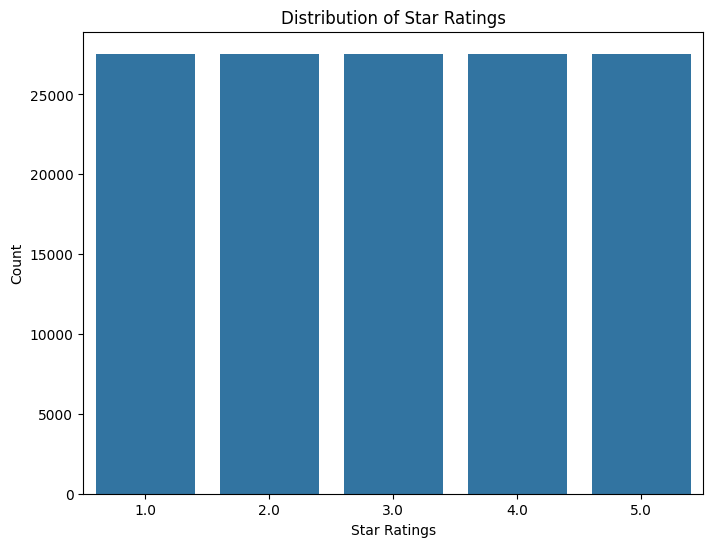

In [32]:
# General function to generate column chart for any given attribute
def column_chart(attribute, label):
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df_modeling, x=attribute)
    plt.xlabel(label)
    plt.ylabel('Count')
    plt.title(f'Distribution of {label}')
    plt.show()

print(df_modeling['star_rating'].value_counts())
column_chart('star_rating', 'Star Ratings')

In [33]:
# 1. Print dataset general overview (Total rows and columns)
print(f"DATA OVERALL ")
print(f"Total Rows (Rows): {df_modeling.shape[0]}")
print(f"Total Columns (Columns): {df_modeling.shape[1]}")
print("-" * 30)

# 2. Create detailed Data Profile table for each column
profile_data = []
for col in df_modeling.columns:
    profile_data.append({
        'Column': col,
        'Data Type': df_modeling[col].dtype,
        'Non-Null Count': df_modeling[col].notnull().sum(),
        'Null Count': df_modeling[col].isnull().sum(),
        'Unique Values': df_modeling[col].nunique(),
        'Min / Start Date': df_modeling[col].min() if df_modeling[col].dtype != 'object' else '-',
        'Max / End Date': df_modeling[col].max() if df_modeling[col].dtype != 'object' else '-'
    })

data_profile_df = pd.DataFrame(profile_data)
data_profile_df


DATA OVERALL 
Total Rows (Rows): 137755
Total Columns (Columns): 18
------------------------------


,Column,Data Type,Non-Null Count,Null Count,Unique Values,Min / Start Date,Max / End Date
0,marketplace,object,137755,0,1,-,-
1,customer_id,int64,137755,0,122793,10943,53096553
2,review_id,object,137755,0,137755,-,-
3,product_id,object,137755,0,23345,-,-
4,product_parent,int64,137755,0,11629,225472,999988076
5,product_title,object,137755,0,18554,-,-
6,product_category,object,137755,0,34,-,-
7,star_rating,float64,137755,0,5,1.0,5.0
8,helpful_votes,float64,137755,0,798,3.0,27550.0
9,total_votes,float64,137755,0,871,3.0,28727.0


## 6. REPRODUCIBILITY & ETHICS DECLARATION

### 6.1 Reproducibility Setup

To ensure full reproducibility of this analysis, all experiments and data processing steps are standardized through the following environment configurations:
* **Platform:** Google Colab (Standard T4 GPU runtime environment).
* **Python Version:** Python 3.13.
* **Dependency Management:** All required core libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `kaggle`) along with their exact versions are explicitly specified in the `requirements.txt` file and can be installed via `pip install -r requirements.txt`.
* **Data Pipeline Access:** Raw datasets are dynamically retrieved from Kaggle (`nguynthehao/amazon-book-reviews`) using secure Kaggle API token authentication (`kaggle.json`), ensuring seamless replication from raw data ingestion to final data cleaning and modeling preparation.
---
### 6.2 Ethics, Privacy & AI Declaration
- **Privacy** (PII): No personal data
- **AI Tool Declaration**: Claude, Gemini, ChatGPT for Debugging, checking for grammar errors.